# Basketball ONNX Video Inference

- Run **YOLOX-Tiny, YOLOX-Nano, YOLO11n, and RF-DETR Small** one at a time.
- Process the full dribbling clip with the same confidence threshold and
  provider mode for every model.
- Use the evaluation kernel and framework-neutral ONNX adapters.
- No tracking or ground truth: coverage is descriptive, and annotated previews
  are for qualitative review only.

In [1]:
from __future__ import annotations

import json
import os
import platform
import tempfile
from datetime import UTC, datetime
from itertools import islice
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import onnxruntime as ort
import pandas as pd
from detection_common.runtime import configure_stdio_relative_path
from detection_common.utils.digest import file_digest
from detection_common.utils.json_io import print_json, read_json, write_json
from IPython.display import Markdown, display
from PIL import Image

from detection_evaluation.config import (
    DATA_ROOT,
    OUTPUT_ROOT,
    SUBPROJECT_ROOT,
    WORKSPACE_ROOT,
)
from detection_evaluation.onnx_inference import ModelFamilies, provider_modes
from detection_evaluation.video_inference import (
    comparison_rows,
    describe_model,
    discover_video_models,
    portable_path,
    run_video_inference,
)

configure_stdio_relative_path(WORKSPACE_ROOT)

## 1. Configuration

The default `cpu_reference` explicitly requests `CPUExecutionProvider`, allowing
comparison with the earlier CPU video baseline. Set `PROVIDER_MODE` to
`coreml_first` to request CoreML with CPU fallback for unsupported graph nodes..

All frames are processed at the source dimensions and nominal playback rate.
The annotated MP4 contains no audio. Original training dataset files are not
required: category IDs come from each run's saved canonical mapping.

In [2]:
VIDEO_PATH = (
    DATA_ROOT
    / "sources"
    / "downloads"
    / "basketball_videos"
    / "basketball_dribbling.webm"
)
RUNS_DIR = OUTPUT_ROOT / "runs" / "basketball"
ARTIFACT_ROOT = OUTPUT_ROOT / "evaluation" / "video_inference"
COREML_CACHE_ROOT = OUTPUT_ROOT / "cache" / "onnxruntime" / "coreml"

CONFIDENCE_THRESHOLD = 0.25
PROVIDER_MODE = "cpu_reference"  # Alternative: "coreml_first".

MODEL_DECLARATIONS = (
    ("yolox_tiny", ModelFamilies.YOLOX, "yolox_tiny*/**/*.onnx"),
    ("yolox_nano", ModelFamilies.YOLOX, "yolox_nano*/**/*.onnx"),
    ("yolo11n", ModelFamilies.YOLO11, "yolo11n*/**/*.onnx"),
    ("rfdetr_small", ModelFamilies.RFDETR, "rfdetr_small*/**/*.onnx"),
)

## 2. Discover eligible exports

Select the newest eligible ONNX by file modification time, breaking ties by path. All
selected runs must share a canonical source fingerprint.

Saved NMS and maximum-detection settings are reused where available. The
defaults are YOLOX IoU 0.65, YOLO11n IoU 0.70, and maximum 300 detections.
RF-DETR uses no NMS. Each selected graph will pass `onnx.checker` and the family
contract check before processing; an incompatible graph fails visibly.

In [3]:
models, excluded = discover_video_models(
    RUNS_DIR, MODEL_DECLARATIONS, confidence_threshold=CONFIDENCE_THRESHOLD
)
if excluded:
    display(pd.DataFrame(excluded))
else:
    print("No ineligible ONNX candidates were found.")

model_metadata = [describe_model(model) for model in models]
discovery = pd.DataFrame(model_metadata)
discovery["modified_utc"] = pd.to_datetime(discovery["onnx_mtime_ns"], utc=True)
discovery["size_mb"] = discovery["onnx_size_bytes"] / 1024**2
with pd.option_context("display.max_colwidth", None):
    display(
        discovery[
            [
                "model",
                "run_dir",
                "onnx_path",
                "modified_utc",
                "size_mb",
                "confidence_threshold",
                "nms_iou",
                "max_detections",
            ]
        ]
    )

,model,onnx_path,reason
0,yolox_tiny,outputs/runs/basketball/yolox_tiny_20261105T16...,Requires full data without smoke or batch limits
1,yolox_nano,outputs/runs/basketball/yolox_nano_20261105T16...,Requires full data without smoke or batch limits
2,yolo11n,outputs/runs/basketball/yolo11n_20261105T16004...,Requires full data without smoke or batch limits


,model,run_dir,onnx_path,modified_utc,size_mb,confidence_threshold,nms_iou,max_detections
0,yolox_tiny,outputs/runs/basketball/yolox_tiny_20261105T170915,outputs/runs/basketball/yolox_tiny_20261105T170915/weights/best_ckpt.onnx,2026-11-05 20:03:00+00:00,19.232903,0.25,0.65,300
1,yolox_nano,outputs/runs/basketball/yolox_nano_20261105T200341,outputs/runs/basketball/yolox_nano_20261105T200341/weights/best_ckpt.onnx,2026-11-05 22:55:30+00:00,3.483143,0.25,0.65,300
2,yolo11n,outputs/runs/basketball/yolo11n_20261105T160703,outputs/runs/basketball/yolo11n_20261105T160703/weights/best.onnx,2026-11-05 17:08:57+00:00,10.075570,0.25,0.70,300
3,rfdetr_small,outputs/runs/basketball/rfdetr_small_20261106T124419,outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_total.onnx,2026-11-06 14:12:20+00:00,109.801916,0.25,NaN,300


## 3. Check runtime and input

Session loading and graph validation happen once per model. Configured and
actual session providers are recorded in each summary. CoreML compilation
caches remain under the shared output root.

In [4]:
if not VIDEO_PATH.is_file():
    raise FileNotFoundError(VIDEO_PATH)
runtime = {
    "onnxruntime": ort.__version__,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "available_providers": ort.get_available_providers(),
}
modes = {}
for model in models:
    choices = {
        mode.name: mode
        for mode in provider_modes(
            runtime["available_providers"], COREML_CACHE_ROOT, model.spec.name
        )
    }
    if PROVIDER_MODE not in choices:
        raise ValueError(f"Unknown provider mode: {PROVIDER_MODE}")
    mode = choices[PROVIDER_MODE]
    if not mode.available:
        raise RuntimeError(mode.unavailable_reason)
    modes[model.spec.name] = mode

video_metadata = {
    "video_path": portable_path(VIDEO_PATH),
    "video_sha256": file_digest(VIDEO_PATH),
}
print_json({**runtime, **video_metadata, "provider_mode": PROVIDER_MODE})

{
  "available_providers": [
    "CoreMLExecutionProvider",
    "AzureExecutionProvider",
    "CPUExecutionProvider"
  ],
  "machine": "arm64",
  "onnxruntime": "1.30.0",
  "platform": "macOS-26.6.2-arm64-arm-64bit",
  "provider_mode": "cpu_reference",
  "video_path": "data/sources/downloads/basketball_videos/basketball_dribbling.webm",
  "video_sha256": "1a592d92d8359729b679067977b295526fa376a9b15f92d3d7be3671941aa023"
}


## 4. Process the complete clip

Each execution creates a fresh directory and preserves previous outputs.
Empty-detection frames remain in both the video and JSONL log. 

**Timing boundaries:**

- Processing seconds include capture/writer setup, decoding, RGB conversion,
  preprocessing, inference, postprocessing, drawing, JSONL/video writes, and
  output closure. Discovery, hashing, session loading, graph validation,
  metadata reporting, and previews are excluded.
- Mean inference milliseconds measure RGB conversion, preprocessing,
  `session.run`, and postprocessing once per processed frame. Decoding,
  drawing, logging, and video writing are excluded.

This is one full-video pass, including its first inference. There are no
warm-up calls or repeated benchmark samples, so these timings differ from a
warmed single-image benchmark.

In [5]:
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
execution_dir = Path(
    tempfile.mkdtemp(
        prefix=datetime.now(UTC).strftime("%Y%m%dT%H%M%SZ_"), dir=ARTIFACT_ROOT
    )
)
write_json(
    execution_dir / "selection.json",
    {
        "schema_version": 1,
        "execution_id": execution_dir.name,
        **video_metadata,
        "runtime": runtime,
        "provider_mode": PROVIDER_MODE,
        "models": model_metadata,
        "excluded_candidates": excluded,
    },
    allow_nan=False,
)
print(f"Artifacts: {portable_path(execution_dir)}")

summaries = []
for model in models:
    name = model.spec.name
    print(f"Processing full clip: {name}", flush=True)
    try:
        summary = run_video_inference(
            model, VIDEO_PATH, execution_dir / name, modes[name]
        )
    except Exception as error:  # noqa: BLE001 - report failures and review partials.
        print(f"ERROR: {name}: {error}", flush=True)
        summary = read_json(execution_dir / name / "summary.json")
    summaries.append(summary)
    print_json(summary, title=f"{name}: {summary['status']}")

Artifacts: outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs
Processing full clip: yolox_tiny


yolox_tiny: completed
{
  "actual_providers": [
    "CPUExecutionProvider"
  ],
  "audio_preserved": false,
  "class_mapping": [
    {
      "category_id": 1,
      "class_name": "basketball",
      "model_class_id": 0
    }
  ],
  "confidence_threshold": 0.25,
  "configured_providers": [
    "CPUExecutionProvider"
  ],
  "family": "yolox",
  "frames_with_detections": 1055,
  "frames_without_detections": 703,
  "max_detections": 300,
  "mean_inference_ms": 75.56748076126367,
  "model": "yolox_tiny",
  "nms_iou": 0.65,
  "onnx_mtime_ns": 1793908980000000000,
  "onnx_path": "outputs/runs/basketball/yolox_tiny_20261105T170915/weights/best_ckpt.onnx",
  "onnx_sha256": "e3cd982c4b37f570f7569c48679f4020e62ff142d6b07569ceab423780a05f85",
  "onnx_size_bytes": 20167160,
  "processed_frames": 1758,
  "processing_fps": 12.772585364509101,
  "processing_seconds": 137.63853987501352,
  "provider_mode": "cpu_reference",
  "run_dir": "outputs/runs/basketball/yolox_tiny_20261105T170915",
  "runtime": 

yolox_nano: completed
{
  "actual_providers": [
    "CPUExecutionProvider"
  ],
  "audio_preserved": false,
  "class_mapping": [
    {
      "category_id": 1,
      "class_name": "basketball",
      "model_class_id": 0
    }
  ],
  "confidence_threshold": 0.25,
  "configured_providers": [
    "CPUExecutionProvider"
  ],
  "family": "yolox",
  "frames_with_detections": 1177,
  "frames_without_detections": 581,
  "max_detections": 300,
  "mean_inference_ms": 32.90975930922679,
  "model": "yolox_nano",
  "nms_iou": 0.65,
  "onnx_mtime_ns": 1793919330000000000,
  "onnx_path": "outputs/runs/basketball/yolox_nano_20261105T200341/weights/best_ckpt.onnx",
  "onnx_sha256": "1af2fd17c337ab43069856007273471e72da745a4586fc63dc66a03961ffe5af",
  "onnx_size_bytes": 3652340,
  "processed_frames": 1758,
  "processing_fps": 27.989557231147362,
  "processing_seconds": 62.80913933299598,
  "provider_mode": "cpu_reference",
  "run_dir": "outputs/runs/basketball/yolox_nano_20261105T200341",
  "runtime": {


yolo11n: completed
{
  "actual_providers": [
    "CPUExecutionProvider"
  ],
  "audio_preserved": false,
  "class_mapping": [
    {
      "category_id": 1,
      "class_name": "basketball",
      "model_class_id": 0
    }
  ],
  "confidence_threshold": 0.25,
  "configured_providers": [
    "CPUExecutionProvider"
  ],
  "family": "yolo11",
  "frames_with_detections": 1067,
  "frames_without_detections": 691,
  "max_detections": 300,
  "mean_inference_ms": 42.07099317885571,
  "model": "yolo11n",
  "nms_iou": 0.7,
  "onnx_mtime_ns": 1793898537000000000,
  "onnx_path": "outputs/runs/basketball/yolo11n_20261105T160703/weights/best.onnx",
  "onnx_sha256": "42f6ebbf116c8ea509c812f4bbd0e4356abba585b5c346cc18552e0f23a3b038",
  "onnx_size_bytes": 10565001,
  "processed_frames": 1758,
  "processing_fps": 22.27590810630854,
  "processing_seconds": 78.91934154200135,
  "provider_mode": "cpu_reference",
  "run_dir": "outputs/runs/basketball/yolo11n_20261105T160703",
  "runtime": {
    "host": "SBs-

rfdetr_small: completed
{
  "actual_providers": [
    "CPUExecutionProvider"
  ],
  "audio_preserved": false,
  "class_mapping": [
    {
      "category_id": 1,
      "class_name": "basketball",
      "model_class_id": 0
    }
  ],
  "confidence_threshold": 0.25,
  "configured_providers": [
    "CPUExecutionProvider"
  ],
  "family": "rf-detr",
  "frames_with_detections": 1366,
  "frames_without_detections": 392,
  "max_detections": 300,
  "mean_inference_ms": 412.0450525966275,
  "model": "rfdetr_small",
  "nms_iou": null,
  "onnx_mtime_ns": 1793974340000000000,
  "onnx_path": "outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_total.onnx",
  "onnx_sha256": "3254af0ccc47c588cb1838f365eea7d4f30084c02d8b2be50cfe2730374a2890",
  "onnx_size_bytes": 115135654,
  "processed_frames": 1758,
  "processing_fps": 2.409412447709731,
  "processing_seconds": 729.6384650419932,
  "provider_mode": "cpu_reference",
  "run_dir": "outputs/runs/basketball/rfdetr_small_20261106T124419",


## 5. Inspect artifacts and aligned previews

`frame_index` is zero-based. `timestamp_s = frame_index / source_fps` is a
**nominal timestamp**, not an exact WebM presentation timestamp. Each detection
contains a source-pixel `[x, y, width, height]` box, center coordinates, saved
category ID, class name, and confidence. Missed detections remain `[]`.

Follow the artifact links for full video review. The first, middle, and last
annotated frames are aligned across models and reduced to thumbnails before
display. They support qualitative review, not precision, recall, or AP.

In [6]:
for summary in summaries:
    name = summary["model"]
    output_dir = execution_dir / name
    links = []
    for filename in ("annotated.mp4", "detections.jsonl", "summary.json"):
        path = output_dir / filename
        if path.is_file():
            href = os.path.relpath(path, SUBPROJECT_ROOT / "notebooks")
            links.append(f"[{filename}]({href})")
    display(Markdown(f"**{name}**: " + " · ".join(links)))
    if (output_dir / "detections.jsonl").is_file():
        with (output_dir / "detections.jsonl").open(encoding="utf-8") as stream:
            for line in islice(stream, 3):
                print_json(json.loads(line))
    if summary["warnings"]:
        print_json(summary["warnings"], title=f"{name} frame count warnings:")

**yolox_tiny**: [annotated.mp4](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolox_tiny/annotated.mp4) · [detections.jsonl](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolox_tiny/detections.jsonl) · [summary.json](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolox_tiny/summary.json)

{
  "detections": [
    {
      "bbox": [
        445.5779113769531,
        63.985565185546875,
        315.7817687988281,
        342.66790771484375
      ],
      "category_id": 1,
      "center_x": 603.4687957763672,
      "center_y": 235.31951904296875,
      "class_name": "basketball",
      "confidence": 0.8286951780319214
    }
  ],
  "frame_index": 0,
  "timestamp_s": 0.0
}
{
  "detections": [
    {
      "bbox": [
        361.4676818847656,
        22.833160400390625,
        315.6794738769531,
        330.90826416015625
      ],
      "category_id": 1,
      "center_x": 519.3074188232422,
      "center_y": 188.28729248046875,
      "class_name": "basketball",
      "confidence": 0.9318702816963196
    }
  ],
  "frame_index": 1,
  "timestamp_s": 0.033366700033366704
}
{
  "detections": [
    {
      "bbox": [
        273.19329833984375,
        0.6837158203125,
        336.20404052734375,
        315.4352111816406
      ],
      "category_id": 1,
      "center_x": 441.2953186

**yolox_nano**: [annotated.mp4](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolox_nano/annotated.mp4) · [detections.jsonl](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolox_nano/detections.jsonl) · [summary.json](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolox_nano/summary.json)

{
  "detections": [
    {
      "bbox": [
        422.772216796875,
        60.63056945800781,
        370.1856689453125,
        349.02325439453125
      ],
      "category_id": 1,
      "center_x": 607.8650512695312,
      "center_y": 235.14219665527344,
      "class_name": "basketball",
      "confidence": 0.8243234753608704
    }
  ],
  "frame_index": 0,
  "timestamp_s": 0.0
}
{
  "detections": [
    {
      "bbox": [
        343.5404968261719,
        12.001373291015625,
        343.3702697753906,
        353.60870361328125
      ],
      "category_id": 1,
      "center_x": 515.2256317138672,
      "center_y": 188.80572509765625,
      "class_name": "basketball",
      "confidence": 0.9085930585861206
    }
  ],
  "frame_index": 1,
  "timestamp_s": 0.033366700033366704
}
{
  "detections": [
    {
      "bbox": [
        264.90087890625,
        2.123645782470703,
        351.1922607421875,
        313.4150390625
      ],
      "category_id": 1,
      "center_x": 440.49700927734375

**yolo11n**: [annotated.mp4](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolo11n/annotated.mp4) · [detections.jsonl](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolo11n/detections.jsonl) · [summary.json](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/yolo11n/summary.json)

{
  "detections": [
    {
      "bbox": [
        445.77667236328125,
        75.24041748046875,
        342.66229248046875,
        310.6566467285156
      ],
      "category_id": 1,
      "center_x": 617.1078186035156,
      "center_y": 230.56874084472656,
      "class_name": "basketball",
      "confidence": 0.9344173073768616
    }
  ],
  "frame_index": 0,
  "timestamp_s": 0.0
}
{
  "detections": [
    {
      "bbox": [
        357.8897399902344,
        26.25592803955078,
        323.2684631347656,
        323.5321960449219
      ],
      "category_id": 1,
      "center_x": 519.5239715576172,
      "center_y": 188.02202606201172,
      "class_name": "basketball",
      "confidence": 0.9151071906089783
    }
  ],
  "frame_index": 1,
  "timestamp_s": 0.033366700033366704
}
{
  "detections": [
    {
      "bbox": [
        273.088623046875,
        2.359039306640625,
        328.750732421875,
        292.6592102050781
      ],
      "category_id": 1,
      "center_x": 437.46398925781

**rfdetr_small**: [annotated.mp4](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/rfdetr_small/annotated.mp4) · [detections.jsonl](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/rfdetr_small/detections.jsonl) · [summary.json](../../outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/rfdetr_small/summary.json)

{
  "detections": [
    {
      "bbox": [
        450.4700012207031,
        72.42674255371094,
        334.5918273925781,
        317.9798583984375
      ],
      "category_id": 1,
      "center_x": 617.7659149169922,
      "center_y": 231.4166717529297,
      "class_name": "basketball",
      "confidence": 0.4427141547203064
    }
  ],
  "frame_index": 0,
  "timestamp_s": 0.0
}
{
  "detections": [
    {
      "bbox": [
        805.3628540039062,
        281.7795104980469,
        12.80389404296875,
        13.339080810546875
      ],
      "category_id": 1,
      "center_x": 811.7648010253906,
      "center_y": 288.4490509033203,
      "class_name": "basketball",
      "confidence": 0.5644275546073914
    }
  ],
  "frame_index": 1,
  "timestamp_s": 0.033366700033366704
}
{
  "detections": [
    {
      "bbox": [
        804.5344848632812,
        278.074462890625,
        12.5604248046875,
        12.938140869140625
      ],
      "category_id": 1,
      "center_x": 810.814697265625,

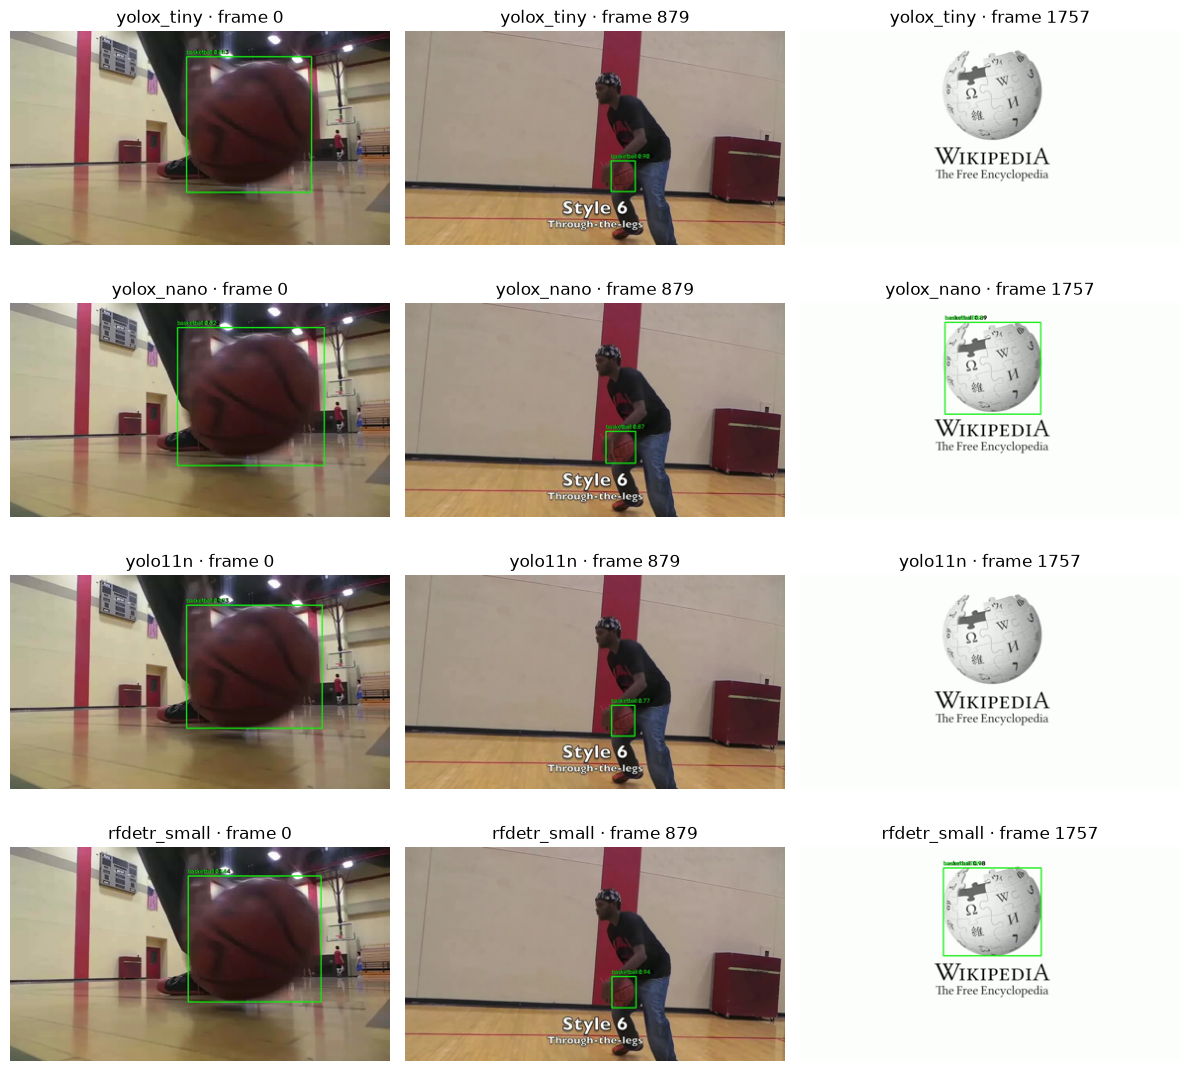

In [7]:
completed = [summary for summary in summaries if summary["status"] == "completed"]
rows = comparison_rows(summaries)  # Also checks matching decoded frame counts.
if completed:
    frame_count = completed[0]["processed_frames"]
    preview_indices = (0, frame_count // 2, frame_count - 1)
    figure, axes = plt.subplots(
        len(completed), 3, figsize=(12, 2.8 * len(completed)), squeeze=False
    )
    for row, summary in enumerate(completed):
        capture = cv2.VideoCapture(
            str(execution_dir / summary["model"] / "annotated.mp4")
        )
        try:
            for column, index in enumerate(preview_indices):
                capture.set(cv2.CAP_PROP_POS_FRAMES, index)
                readable, frame = capture.read()
                if not readable:
                    raise RuntimeError(
                        f"Cannot preview {summary['model']} frame {index}"
                    )
                preview = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                preview.thumbnail((384, 216))
                axes[row, column].imshow(preview)
                axes[row, column].set_title(f"{summary['model']} · frame {index}")
                axes[row, column].axis("off")
        finally:
            capture.release()
    figure.tight_layout()
    display(figure)
    plt.close(figure)

## 6. Compare full-video processing

Only completed runs enter the table. Detection counts and frames with/without
detections describe coverage; there are no frame annotations to measure
accuracy. Processing FPS includes video I/O, while mean inference latency uses
the narrower boundary defined above. Reported source frame counts are advisory;
discrepancies are flagged in each summary.

In [8]:
comparison = pd.DataFrame(rows)
comparison.to_csv(execution_dir / "comparison.csv", index=False)
display(comparison)
print(f"Comparison: {portable_path(execution_dir / 'comparison.csv')}")
failed = [summary["model"] for summary in summaries if summary["status"] != "completed"]
if failed:
    raise RuntimeError("Video inference failed for: " + ", ".join(failed))

,model,provider_mode,processed_frames,total_detections,frames_with_detections,frames_without_detections,processing_seconds,processing_fps,mean_inference_ms
0,yolox_tiny,cpu_reference,1758,1144,1055,703,137.638540,12.772585,75.567481
1,yolox_nano,cpu_reference,1758,1197,1177,581,62.809139,27.989557,32.909759
2,yolo11n,cpu_reference,1758,1155,1067,691,78.919342,22.275908,42.070993
3,rfdetr_small,cpu_reference,1758,1459,1366,392,729.638465,2.409412,412.045053


Comparison: outputs/evaluation/video_inference/20261112T001117Z_5wtyb6gs/comparison.csv
